# Fork detection baselines: DINO + MLP and Faster R-CNN
Real: `jhehli/tem-fork-detection` · synthetic: `jhehli/synthetic-tem-images` · greedy point matching within 75 px (same protocol as the segmentation/graph pipeline).

In [1]:
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import data, report
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.dpi"] = 60

## Data
`sbatch slurm/data.sbatch` downloads both datasets and caches 0.5× uint8 images (1–99 percentile stretch).

In [2]:
# data.download()
pd.DataFrame([dict(dataset=d, split=s, images=len(rs), replication=int(sum((r["points"][:, 2] == 0).sum() for r in rs)), reversed=int(sum((r["points"][:, 2] == 1).sum() for r in rs)))
              for d in ("real", "synthetic") for s in ("train", "val", "test") for rs in [[r for r in data.records(d) if r["split"] == s]]])

,dataset,split,images,replication,reversed
0,real,train,242,60,190
1,real,val,43,10,36
2,real,test,100,45,77
3,synthetic,train,1296,432,432
4,synthetic,val,144,48,48
5,synthetic,test,144,48,48


## Train (SLURM)
Each run writes `results/<model>_<dataset>_s<seed>/{preds.csv,metrics.json}`; the score threshold is picked on val.

In [3]:
ABLATIONS = [("dinov2", "--backbone vit_small_patch14_reg4_dinov2.lvd142m"), ("dino-ft4", "--unfreeze 4"), ("dino-b", "--backbone vit_base_patch16_dinov3.lvd1689m")]
JOBS = [f"slurm/{m}.sbatch --dataset {d} --seed {s}" for m in ("dino", "frcnn") for d in ("real", "synthetic") for s in (0, 1, 2)]
JOBS += [f"slurm/dino.sbatch --dataset {d} {a} --name {n}_{d}_s0" for d in ("real", "synthetic") for n, a in ABLATIONS]
SUBMIT = False
if SUBMIT:
    for j in JOBS:
        subprocess.run(["sbatch", *j.split()], check=True)
len(JOBS)

18

## Results on the test sets (mean ± std over seeds)

In [4]:
tabs = report.write_tables()
tabs["real_main"]

,P,R,F1,P (cls),R (cls),F1 (cls),seeds
model,,,,,,,
DINOv3 ViT-S/16 + MLP,0.22 ± 0.07,0.33 ± 0.11,0.25 ± 0.02,0.20 ± 0.06,0.31 ± 0.11,0.23 ± 0.02,3
DINOv2 ViT-S/14 (registers) + MLP,0.27 ± 0.01,0.41 ± 0.02,0.32 ± 0.01,0.25 ± 0.00,0.39 ± 0.01,0.31 ± 0.00,3
"DINOv3 ViT-S/16 + MLP, last 4 blocks tuned",0.21 ± 0.01,0.70 ± 0.03,0.32 ± 0.01,0.19 ± 0.01,0.64 ± 0.03,0.29 ± 0.01,3
DINOv3 ViT-B/16 + MLP,0.15,0.57,0.23,0.13,0.50,0.20,1
Faster R-CNN R50-FPN v2,0.35 ± 0.02,0.74 ± 0.06,0.47 ± 0.03,0.33 ± 0.01,0.70 ± 0.03,0.45 ± 0.01,3


In [5]:
tabs["real_per_class"]

,rep P,rep R,rev P,rev R,rep P (cls),rep R (cls),rev P (cls),rev R (cls),seeds
model,,,,,,,,,
DINOv3 ViT-S/16 + MLP,0.04 ± 0.07,0.08 ± 0.05,0.22 ± 0.07,0.48 ± 0.16,0.04 ± 0.07,0.02 ± 0.04,0.21 ± 0.06,0.48 ± 0.16,3
DINOv2 ViT-S/14 (registers) + MLP,0.33 ± 0.09,0.16 ± 0.05,0.26 ± 0.01,0.55 ± 0.03,0.30 ± 0.07,0.13 ± 0.03,0.25 ± 0.01,0.55 ± 0.03,3
"DINOv3 ViT-S/16 + MLP, last 4 blocks tuned",0.22 ± 0.04,0.44 ± 0.03,0.21 ± 0.01,0.85 ± 0.03,0.19 ± 0.02,0.33 ± 0.01,0.19 ± 0.01,0.82 ± 0.04,3
DINOv3 ViT-B/16 + MLP,0.11,0.24,0.15,0.77,0.08,0.07,0.13,0.75,1
Faster R-CNN R50-FPN v2,0.56 ± 0.09,0.59 ± 0.12,0.30 ± 0.03,0.82 ± 0.03,0.53 ± 0.11,0.53 ± 0.07,0.29 ± 0.02,0.81 ± 0.01,3


In [6]:
tabs["synthetic_main"]

,P,R,F1,P (cls),R (cls),F1 (cls),seeds
model,,,,,,,
DINOv3 ViT-S/16 + MLP,0.64 ± 0.02,0.62 ± 0.03,0.63 ± 0.00,0.64 ± 0.02,0.62 ± 0.03,0.63 ± 0.00,3
DINOv2 ViT-S/14 (registers) + MLP,0.68 ± 0.03,0.65 ± 0.02,0.66 ± 0.00,0.67 ± 0.03,0.64 ± 0.02,0.66 ± 0.01,3
"DINOv3 ViT-S/16 + MLP, last 4 blocks tuned",0.75 ± 0.04,0.77 ± 0.06,0.76 ± 0.01,0.75 ± 0.04,0.77 ± 0.06,0.76 ± 0.01,3
DINOv3 ViT-B/16 + MLP,0.68,0.78,0.73,0.68,0.78,0.73,1
Faster R-CNN R50-FPN v2,0.93 ± 0.02,0.96 ± 0.02,0.95 ± 0.00,0.93 ± 0.02,0.96 ± 0.02,0.95 ± 0.00,3


In [7]:
tabs["synthetic_density"]

,DINOv3 ViT-S/16 + MLP F1,DINOv3 ViT-S/16 + MLP F1 (cls),DINOv2 ViT-S/14 (registers) + MLP F1,DINOv2 ViT-S/14 (registers) + MLP F1 (cls),"DINOv3 ViT-S/16 + MLP, last 4 blocks tuned F1","DINOv3 ViT-S/16 + MLP, last 4 blocks tuned F1 (cls)",DINOv3 ViT-B/16 + MLP F1,DINOv3 ViT-B/16 + MLP F1 (cls),Faster R-CNN R50-FPN v2 F1,Faster R-CNN R50-FPN v2 F1 (cls)
density,,,,,,,,,,
f1-3,0.84 ± 0.03,0.84 ± 0.03,0.72 ± 0.02,0.72 ± 0.02,0.92 ± 0.07,0.92 ± 0.07,0.80,0.80,0.99 ± 0.03,0.99 ± 0.03
f3-8,0.71 ± 0.03,0.71 ± 0.03,0.83 ± 0.03,0.83 ± 0.03,0.86 ± 0.03,0.86 ± 0.03,0.82,0.82,0.96 ± 0.05,0.96 ± 0.05
f8-13,0.64 ± 0.00,0.64 ± 0.00,0.62 ± 0.06,0.62 ± 0.06,0.80 ± 0.06,0.80 ± 0.06,0.80,0.80,1.00 ± 0.00,1.00 ± 0.00
f13-18,0.58 ± 0.01,0.58 ± 0.01,0.57 ± 0.03,0.57 ± 0.03,0.64 ± 0.03,0.64 ± 0.03,0.67,0.67,0.91 ± 0.06,0.91 ± 0.06
f18-23,0.55 ± 0.01,0.55 ± 0.01,0.80 ± 0.02,0.80 ± 0.02,0.73 ± 0.07,0.73 ± 0.07,0.69,0.69,0.96 ± 0.04,0.96 ± 0.04
f23-28,0.64 ± 0.02,0.64 ± 0.02,0.70 ± 0.05,0.70 ± 0.05,0.78 ± 0.06,0.78 ± 0.06,0.73,0.73,0.94 ± 0.02,0.94 ± 0.02
f28-33,0.48 ± 0.02,0.48 ± 0.02,0.64 ± 0.02,0.58 ± 0.05,0.71 ± 0.06,0.71 ± 0.06,0.79,0.79,0.93 ± 0.03,0.93 ± 0.03
f33-38,0.59 ± 0.02,0.59 ± 0.02,0.43 ± 0.00,0.43 ± 0.00,0.67 ± 0.03,0.67 ± 0.03,0.56,0.56,0.91 ± 0.03,0.91 ± 0.03


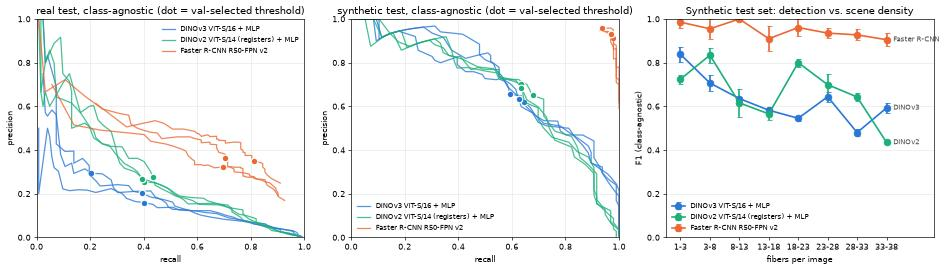

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
report.pr_curve("real", ax=ax[0])
report.pr_curve("synthetic", ax=ax[1])
report.density_plot(ax=ax[2])
fig.tight_layout()

## Example predictions (real test set)

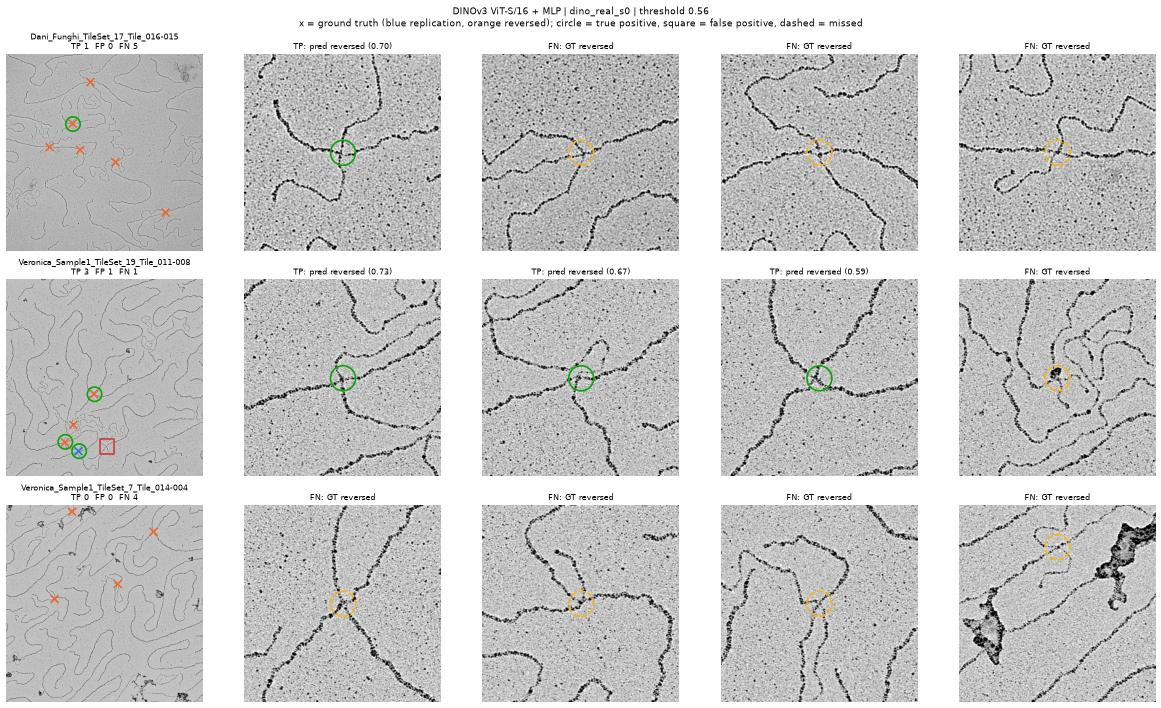

In [9]:
report.show("dino_real_s0", n=3);

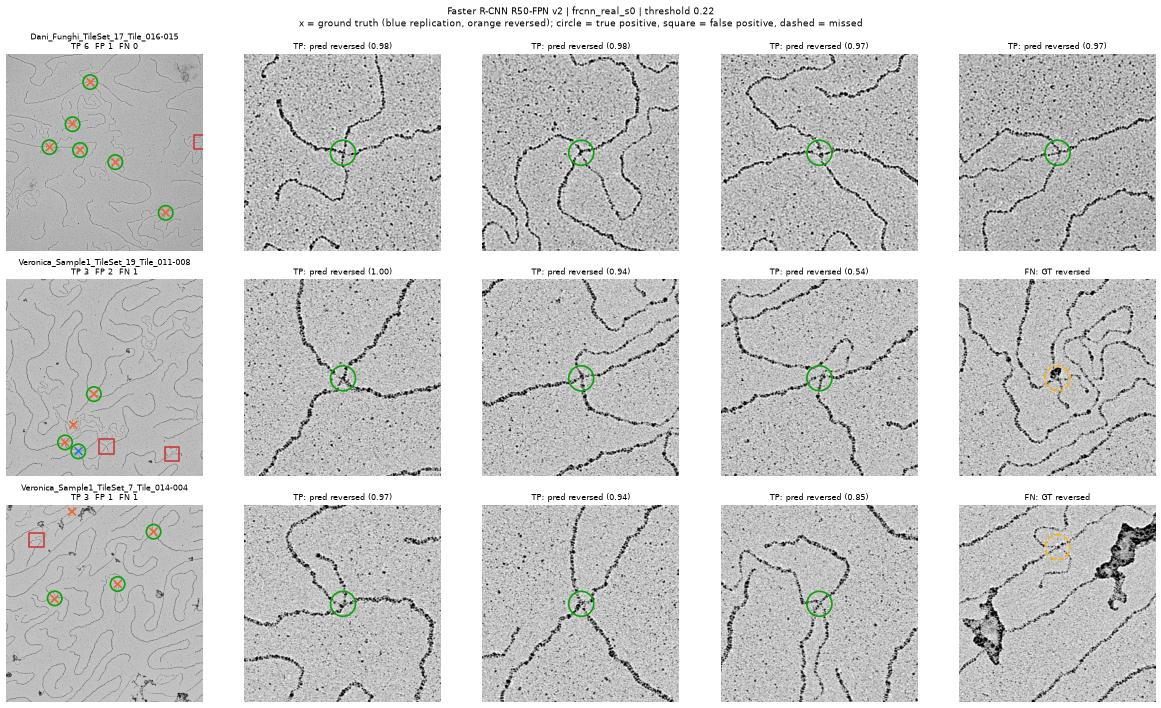

In [10]:
report.show("frcnn_real_s0", n=3);

## Example predictions (synthetic test set)

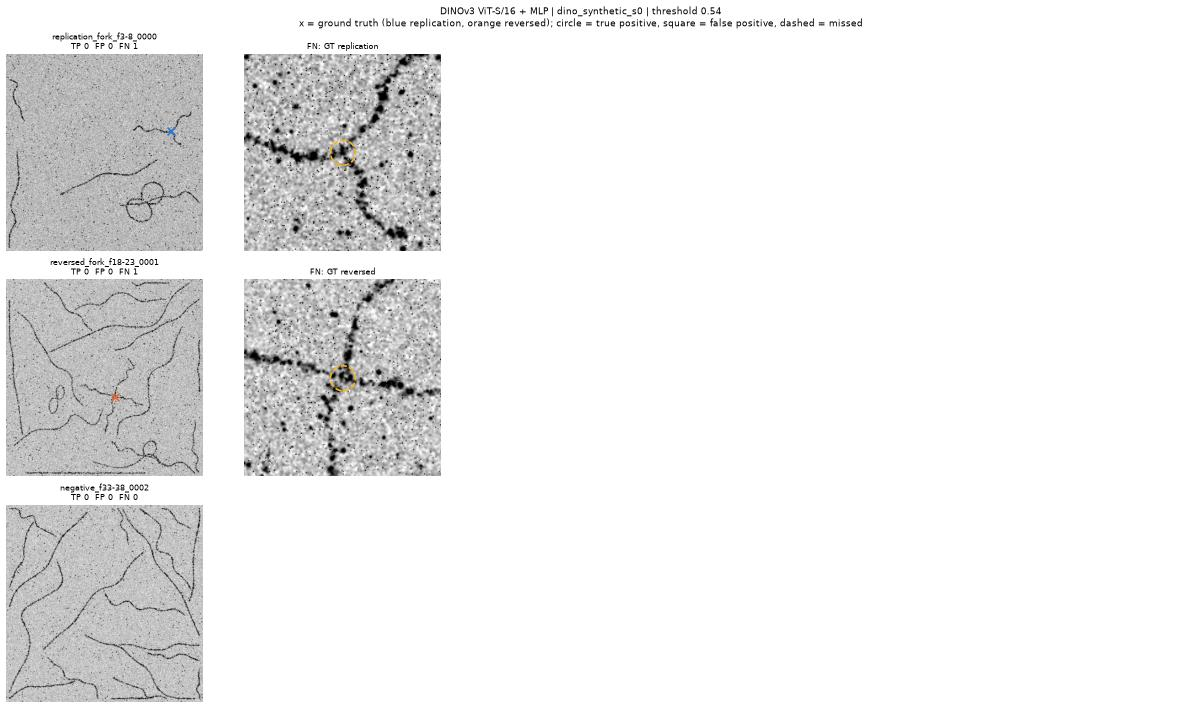

In [11]:
ids = ["replication_fork_f3-8_0000", "reversed_fork_f18-23_0001", "negative_f33-38_0002"]
report.show("dino_synthetic_s0", ids=ids);

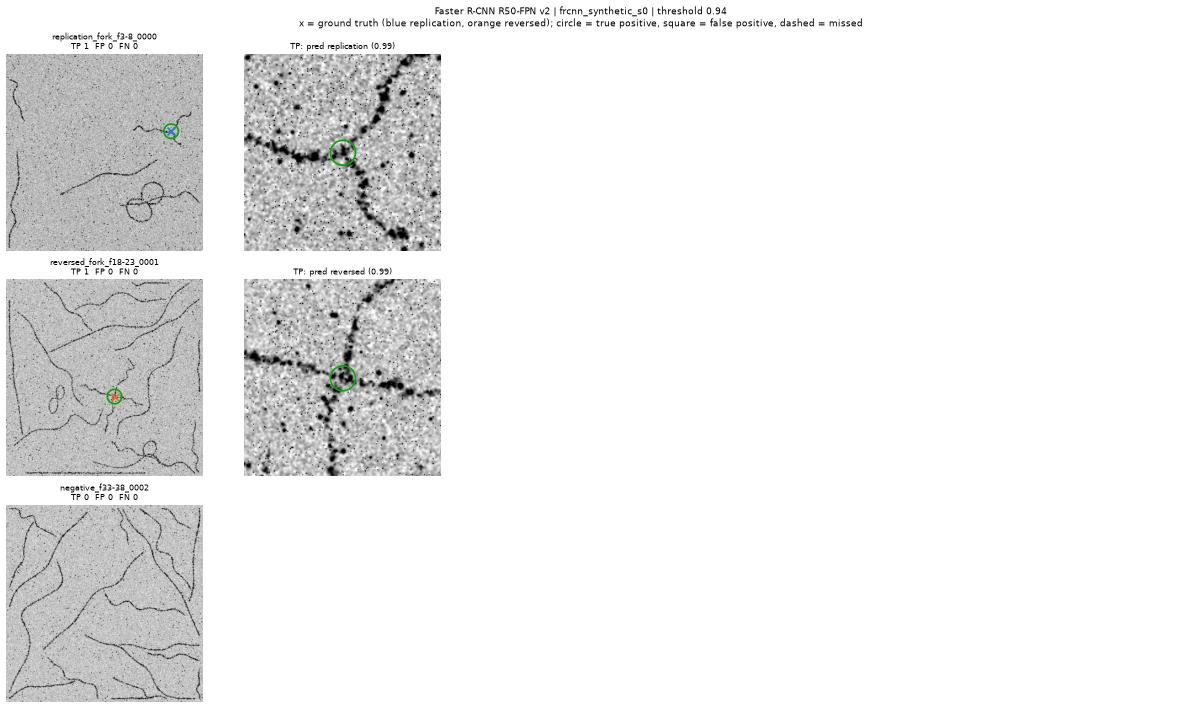

In [12]:
report.show("frcnn_synthetic_s0", ids=ids);

## Synthetic generator
Lean port of `Sythetic_TEM_Images`: bit-identical masks, junctions and TEM to the original code. Full dataset: `SPLIT=train sbatch slurm/synth.sbatch`, then `python -m synthetic.generate --split train --merge` (same for `test`).

{'split': 'test',
 'class': 'reversed_fork',
 'fiber_min': 1,
 'fiber_max': 3,
 'seed': 1100042,
 'junction_x': 567.0,
 'junction_y': 166.0,
 'mask': 'masks/reversed_fork/reversed_fork_f1-3_0000.png',
 'tem': 'tem/reversed_fork/reversed_fork_f1-3_0000.png'}

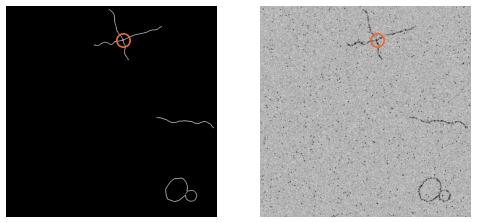

In [13]:
from synthetic.generate import tasks, make
row, mask, tem = make(tasks("test", 1, 1024)[8])
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, im in zip(ax, (mask, tem)):
    a.imshow(im, cmap="gray")
    a.plot(row["junction_x"], row["junction_y"], "o", mfc="none", mec="#eb6834", ms=16, mew=2)
    a.axis("off")
row

In [14]:
from huggingface_hub import hf_hub_download
from PIL import Image
from synthetic.masks import Cfg, make_mask
split, cls, fibers, i, seed, size = tasks("train", 1, 4096)[0]
m, j = make_mask(cls, seed, Cfg(size, fibers))
hf = np.array(Image.open(hf_hub_download(data.SYN_REPO, f"train/masks/{cls}/{cls}_f1-3_0000.png", repo_type="dataset")))[..., 0] > 0
(m == hf).all(), j

(np.True_, (854.0, 2790.0))